# 03 - CNN+LSTM para Reconocimiento de Palabras en ASL

## Objetivo
Implementar y entrenar un modelo baseline CNN+LSTM para clasificar videos de lengua de signos.

## Arquitectura

```
Video [B, T, 3, 224, 224]
         ↓
    ┌─────────────┐
    │   ResNet18  │  ← CNN: extrae features de cada frame
    │  (encoder)  │     Entrada: [B*T, 3, 224, 224]
    └─────────────┘     Salida:  [B*T, 512]
         ↓
    Reshape: [B, T, 512]
         ↓
    ┌─────────────┐
    │    LSTM     │  ← Aprende patrones temporales
    │ (temporal)  │     Entrada: [B, T, 512]
    └─────────────┘     Salida:  [B, hidden_size]
         ↓
    ┌─────────────┐
    │  FC Layer   │  ← Clasificador final
    │(classifier) │     Salida: [B, num_classes]
    └─────────────┘
         ↓
    Predicción: palabra
```

## ¿Por qué esta arquitectura?

1. **ResNet18 pre-entrenado**: Ya sabe extraer features visuales de ImageNet. No partimos de cero.
2. **LSTM**: Diseñado específicamente para secuencias. Tiene "memoria" para recordar frames anteriores.
3. **Simplicidad**: Es un baseline fácil de entender y debuggear antes de probar arquitecturas más complejas.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Configuración del Entorno (Colab vs Local)

Esta celda detecta automáticamente si estás en Colab o local y configura las rutas.

### Si usas Colab:
1. Sube la carpeta `wlasl30` a tu Google Drive en: `Mi unidad/tfg/datasets/wlasl30/`
2. Ejecuta esta celda y acepta los permisos de Drive
3. Los resultados se guardarán en Drive automáticamente

In [2]:
import os
from pathlib import Path
from google.colab import drive

# ============================================
# CONFIGURACIÓN DE RUTAS
# ============================================

# 1. Rutas locales (SSD de Colab - RÁPIDO)
ZIP_LOCAL = Path("/content/wlasl30.zip")  # El archivo que has subido
DATASET_ROOT = Path("/content/wlasl30")   # Donde se va a descomprimir

# 2. Descomprimir (Solo si no está hecho ya)
if not DATASET_ROOT.exists():
    if ZIP_LOCAL.exists():
        print(f"📦 Descomprimiendo {ZIP_LOCAL} en local...")
        # Descomprimir silenciosamente (-q) en /content/
        !unzip -q {ZIP_LOCAL} -d /content/
        print("✅ Descompresión terminada.")
    else:
        print(f"❌ ERROR: No encuentro '{ZIP_LOCAL}'.")
        print("👉 Asegúrate de haber subido 'wlasl30.zip' a la pestaña de archivos de la izquierda.")
        raise FileNotFoundError("Falta el zip")
else:
    print("✅ La carpeta ya estaba descomprimida.")

# 3. Configurar dónde guardar los resultados (Drive - Para no perderlos)
try:
    drive.mount('/content/drive')
    # Ajusta esta ruta si quieres guardarlo en otro sitio de tu Drive
    EXPERIMENTS_DIR = Path("/content/drive/MyDrive/tfg/experiments/word_recognition")
    EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
    print(f"💾 Los resultados se guardarán en: {EXPERIMENTS_DIR}")
except:
    print("⚠️ No se pudo montar Drive. Los resultados se guardarán en local (se borrarán al cerrar).")
    EXPERIMENTS_DIR = Path("/content/experiments")

print(f"\n🎯 DATASET_ROOT final: {DATASET_ROOT}")

📦 Descomprimiendo /content/wlasl30.zip en local...
✅ Descompresión terminada.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
💾 Los resultados se guardarán en: /content/drive/MyDrive/tfg/experiments/word_recognition

🎯 DATASET_ROOT final: /content/wlasl30


## 1. Imports y Configuración

In [3]:
import json
import time
from typing import List, Tuple, Dict, Optional
from datetime import datetime

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
from tqdm.auto import tqdm

# Verificar GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memoria disponible: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Usando dispositivo: cuda
GPU: NVIDIA A100-SXM4-40GB
Memoria disponible: 42.5 GB


## 2. Copiar el DataLoader del Notebook Anterior

Copiamos las clases y funciones que definimos en `02_dataloader.ipynb`.

In [4]:
# Valores de normalización de ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_transforms(split: str, img_size: int = 224):
    """Transformaciones para cada split."""
    if split == "train":
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.RandomHorizontalFlip(p=0.5),
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    else:
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])

In [5]:
class WLASLDataset(Dataset):
    """Dataset para cargar secuencias de video del dataset WLASL."""

    def __init__(
        self,
        root_dir: str,
        split: str = "train",
        transform: Optional[T.Compose] = None,
        max_frames: Optional[int] = None,
        sample_strategy: str = "uniform"
    ):
        self.root_dir = Path(root_dir)
        self.split = split
        self.transform = transform
        self.max_frames = max_frames
        self.sample_strategy = sample_strategy

        with open(self.root_dir / "metadata.json", "r") as f:
            self.metadata = json.load(f)

        self.gloss_to_idx = self.metadata["gloss_to_idx"]
        self.idx_to_gloss = {v: k for k, v in self.gloss_to_idx.items()}
        self.num_classes = len(self.gloss_to_idx)
        self.samples = self._build_sample_list()

        print(f"WLASLDataset [{split}]: {len(self.samples)} videos, {self.num_classes} clases")

    def _build_sample_list(self) -> List[Tuple[Path, int]]:
        samples = []
        split_dir = self.root_dir / self.split

        for gloss_dir in sorted(split_dir.iterdir()):
            if not gloss_dir.is_dir():
                continue
            gloss = gloss_dir.name
            if gloss not in self.gloss_to_idx:
                continue
            label = self.gloss_to_idx[gloss]
            for video_dir in sorted(gloss_dir.iterdir()):
                if video_dir.is_dir():
                    samples.append((video_dir, label))
        return samples

    def _load_frames(self, video_dir: Path) -> torch.Tensor:
        frame_files = sorted(video_dir.glob("*.jpg"))

        if len(frame_files) == 0:
            raise ValueError(f"No hay frames en {video_dir}")

        if self.max_frames and len(frame_files) > self.max_frames:
            if self.sample_strategy == "uniform":
                indices = np.linspace(0, len(frame_files) - 1, self.max_frames, dtype=int)
                frame_files = [frame_files[i] for i in indices]
            else:
                frame_files = frame_files[:self.max_frames]

        frames = []
        for frame_path in frame_files:
            img = Image.open(frame_path).convert("RGB")
            if self.transform:
                img = self.transform(img)
            else:
                img = T.ToTensor()(img)
            frames.append(img)

        return torch.stack(frames)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int, int]:
        video_dir, label = self.samples[idx]
        frames = self._load_frames(video_dir)
        length = frames.shape[0]
        return frames, label, length

    def get_gloss(self, idx: int) -> str:
        return self.idx_to_gloss[idx]

In [6]:
def collate_fn(batch: List[Tuple[torch.Tensor, int, int]]):
    """Collate function que maneja secuencias de longitud variable."""
    frames_list, labels, lengths = zip(*batch)

    labels = torch.tensor(labels, dtype=torch.long)
    lengths = torch.tensor(lengths, dtype=torch.long)

    max_len = max(lengths).item()
    batch_size = len(frames_list)
    C, H, W = frames_list[0].shape[1:]

    frames_padded = torch.zeros(batch_size, max_len, C, H, W)

    for i, frames in enumerate(frames_list):
        seq_len = frames.shape[0]
        frames_padded[i, :seq_len] = frames

    return frames_padded, labels, lengths

## 3. El Modelo CNN+LSTM

### Parte 1: CNN Encoder (ResNet18)

**¿Por qué ResNet18?**
- Pre-entrenado en ImageNet (1.2M imágenes, 1000 clases)
- Ya sabe extraer features visuales generales
- Relativamente pequeño (11M parámetros) pero efectivo
- La última capa antes del clasificador produce un vector de 512 dimensiones

**¿Qué hacemos con ResNet?**
1. Cargamos los pesos pre-entrenados
2. Eliminamos la última capa (que clasifica 1000 clases de ImageNet)
3. Usamos el resto como "extractor de features"

```
ResNet18 original:
  conv1 → bn1 → relu → maxpool → layer1 → layer2 → layer3 → layer4 → avgpool → fc(1000)
                                                                                  ↑
                                                                          Eliminamos esto

ResNet18 como encoder:
  conv1 → bn1 → relu → maxpool → layer1 → layer2 → layer3 → layer4 → avgpool → [512]
                                                                                  ↑
                                                                          Vector de features
```

In [7]:
class CNNEncoder(nn.Module):
    """
    CNN encoder que extrae features de cada frame usando ResNet18.

    Entrada: [B, 3, 224, 224] - Un frame RGB
    Salida:  [B, 512] - Vector de features

    Args:
        pretrained: Si True, usa pesos de ImageNet
        freeze: Si True, congela los pesos (no se entrenan)
    """

    def __init__(self, pretrained: bool = True, freeze: bool = False):
        super().__init__()

        # Cargar ResNet18 pre-entrenado
        if pretrained:
            weights = models.ResNet18_Weights.IMAGENET1K_V1
            self.resnet = models.resnet18(weights=weights)
        else:
            self.resnet = models.resnet18(weights=None)

        # Obtener el tamaño de features antes de la última capa
        self.feature_dim = self.resnet.fc.in_features  # 512 para ResNet18

        # Eliminar la última capa fully-connected
        # nn.Identity() es una capa que no hace nada, solo pasa los datos
        self.resnet.fc = nn.Identity()

        # Opcionalmente congelar los pesos
        if freeze:
            for param in self.resnet.parameters():
                param.requires_grad = False
            print("CNN encoder: pesos congelados (no se entrenarán)")
        else:
            print("CNN encoder: pesos entrenables (fine-tuning)")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [B, 3, 224, 224]
        returns: [B, 512]
        """
        return self.resnet(x)

### Parte 2: LSTM (Temporal Model)

**¿Qué es un LSTM?**

LSTM = Long Short-Term Memory. Es un tipo de red recurrente (RNN) diseñada para secuencias.

**El problema de las RNN normales:**
- Tienen "memoria" muy corta (vanishing gradient)
- Olvidan información de hace muchos pasos

**La solución del LSTM:**
- Tiene "puertas" que controlan qué información recordar y olvidar
- Puede mantener información relevante durante muchos pasos

```
Secuencia de entrada: [frame1_features, frame2_features, ..., frameT_features]
                              ↓              ↓                    ↓
LSTM:                      h1, c1   →    h2, c2    → ... →    hT, cT
                                                                 ↓
Salida: hT (último hidden state) - resume toda la secuencia
```

**Bidirectional LSTM:**
- Procesa la secuencia en ambas direcciones (→ y ←)
- Captura contexto tanto del pasado como del futuro
- Produce el doble de features (2 * hidden_size)

In [8]:
class SignLanguageLSTM(nn.Module):
    """
    Modelo completo CNN+LSTM para clasificación de videos de lengua de signos.

    Entrada: [B, T, 3, 224, 224] - Batch de videos
    Salida:  [B, num_classes] - Logits (probabilidades sin softmax)

    Args:
        num_classes: Número de palabras a clasificar (30 para WLASL30)
        hidden_size: Tamaño del hidden state del LSTM
        num_layers: Número de capas LSTM apiladas
        bidirectional: Si True, LSTM bidireccional
        dropout: Probabilidad de dropout (regularización)
        freeze_cnn: Si True, no entrena el CNN (solo LSTM)
    """

    def __init__(
        self,
        num_classes: int,
        hidden_size: int = 256,
        num_layers: int = 2,
        bidirectional: bool = True,
        dropout: float = 0.3,
        freeze_cnn: bool = False
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        # CNN Encoder
        self.cnn = CNNEncoder(pretrained=True, freeze=freeze_cnn)
        cnn_output_dim = self.cnn.feature_dim  # 512

        # LSTM
        self.lstm = nn.LSTM(
            input_size=cnn_output_dim,      # 512 (features del CNN)
            hidden_size=hidden_size,         # 256
            num_layers=num_layers,           # 2 capas
            batch_first=True,                # Entrada: [B, T, features]
            bidirectional=bidirectional,     # True
            dropout=dropout if num_layers > 1 else 0  # Dropout entre capas
        )

        # Calcular tamaño de salida del LSTM
        # Si bidirectional: 2 * hidden_size (concatena forward y backward)
        lstm_output_dim = hidden_size * 2 if bidirectional else hidden_size

        # Clasificador
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(lstm_output_dim, num_classes)
        )

        print(f"\nSignLanguageLSTM creado:")
        print(f"  CNN: ResNet18 → {cnn_output_dim} features")
        print(f"  LSTM: {num_layers} capas, hidden={hidden_size}, bidirectional={bidirectional}")
        print(f"  Clasificador: {lstm_output_dim} → {num_classes} clases")

    def forward(
        self,
        x: torch.Tensor,
        lengths: torch.Tensor
    ) -> torch.Tensor:
        """
        x: [B, T, C, H, W] - Batch de videos (con padding)
        lengths: [B] - Longitudes reales de cada video
        returns: [B, num_classes] - Logits
        """
        batch_size, max_seq_len, C, H, W = x.shape

        # 1. Pasar todos los frames por el CNN
        # Reshape: [B, T, C, H, W] → [B*T, C, H, W]
        x = x.view(batch_size * max_seq_len, C, H, W)

        # CNN forward: [B*T, C, H, W] → [B*T, 512]
        features = self.cnn(x)

        # Reshape back: [B*T, 512] → [B, T, 512]
        features = features.view(batch_size, max_seq_len, -1)

        # 2. Empaquetar secuencias para el LSTM (ignora padding)
        # Esto es importante para que el LSTM no procese frames de padding
        lengths_cpu = lengths.cpu()  # pack_padded_sequence necesita lengths en CPU
        packed = pack_padded_sequence(
            features,
            lengths_cpu,
            batch_first=True,
            enforce_sorted=False  # Permite que el batch no esté ordenado por longitud
        )

        # 3. LSTM forward
        # packed_output contiene los hidden states de cada timestep
        # (h_n, c_n) son los estados finales
        packed_output, (h_n, c_n) = self.lstm(packed)

        # 4. Obtener el último hidden state
        # h_n shape: [num_layers * num_directions, B, hidden_size]
        # Queremos los últimos hidden states de forward y backward
        if self.bidirectional:
            # Concatenar forward ([-2]) y backward ([-1]) de la última capa
            h_forward = h_n[-2]  # [B, hidden_size]
            h_backward = h_n[-1]  # [B, hidden_size]
            h_final = torch.cat([h_forward, h_backward], dim=1)  # [B, 2*hidden_size]
        else:
            h_final = h_n[-1]  # [B, hidden_size]

        # 5. Clasificador
        logits = self.classifier(h_final)  # [B, num_classes]

        return logits

## 4. Métricas de Evaluación

### Top-1 Accuracy
- La predicción más probable es la correcta
- `(predicciones correctas) / (total) * 100`

### Top-5 Accuracy  
- La palabra correcta está entre las 5 más probables
- Útil cuando hay clases similares/confusas
- Estándar en benchmarks de video (ImageNet usa Top-5)

### Confusion Matrix
- Muestra qué palabras se confunden entre sí
- Ayuda a identificar problemas específicos

In [9]:
def compute_accuracy(logits: torch.Tensor, targets: torch.Tensor, topk: Tuple[int] = (1, 5)):
    """
    Calcula Top-1 y Top-5 accuracy.

    Args:
        logits: [B, num_classes] - Predicciones del modelo (sin softmax)
        targets: [B] - Etiquetas correctas
        topk: Tupla con los k valores a calcular

    Returns:
        Lista de accuracies para cada k

    Ejemplo:
        Si logits = [[0.1, 0.4, 0.3, 0.2]] y target = [1]
        Top-1: La clase 1 (0.4) es la más probable → correcto ✓
        Top-2: Las 2 más probables son [1, 2] → si target=1, correcto ✓
    """
    maxk = max(topk)
    batch_size = targets.size(0)

    # Obtener los índices de las k clases más probables
    # torch.topk devuelve (valores, índices)
    _, pred = logits.topk(maxk, dim=1, largest=True, sorted=True)
    # pred shape: [B, maxk]

    # Comparar con targets
    # Expandir targets para comparar con cada predicción top-k
    pred = pred.t()  # [maxk, B]
    correct = pred.eq(targets.view(1, -1).expand_as(pred))  # [maxk, B]

    accuracies = []
    for k in topk:
        # Para cada k, verificar si alguna de las top-k predicciones es correcta
        correct_k = correct[:k].reshape(-1).float().sum(0)
        acc = correct_k / batch_size * 100.0
        accuracies.append(acc.item())

    return accuracies


def plot_confusion_matrix(
    y_true: List[int],
    y_pred: List[int],
    class_names: List[str],
    save_path: Optional[str] = None
):
    """
    Genera y visualiza la matriz de confusión.

    Args:
        y_true: Lista de etiquetas verdaderas
        y_pred: Lista de predicciones
        class_names: Nombres de las clases
        save_path: Ruta donde guardar la imagen
    """
    cm = confusion_matrix(y_true, y_pred)

    # Normalizar por fila (porcentaje de cada clase real)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt='.1%',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title('Matriz de Confusión (Normalizada)')
    plt.ylabel('Clase Real')
    plt.xlabel('Clase Predicha')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Confusion matrix guardada en: {save_path}")

    plt.show()

## 5. Training y Validation Loops

### ¿Qué pasa en cada época de entrenamiento?

1. **Train loop**:
   - `model.train()` - Activa dropout y batch norm en modo training
   - Forward pass: calcular predicciones
   - Calcular loss (CrossEntropyLoss)
   - Backward pass: calcular gradientes
   - Optimizer step: actualizar pesos

2. **Validation loop**:
   - `model.eval()` - Desactiva dropout
   - `torch.no_grad()` - No calcular gradientes (más rápido)
   - Solo forward pass y métricas

In [10]:
def train_one_epoch(
    model: nn.Module,
    train_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    epoch: int
) -> Dict[str, float]:
    """
    Entrena el modelo por una época.

    Returns:
        Dict con métricas: loss, top1_acc, top5_acc
    """
    model.train()

    total_loss = 0.0
    total_top1 = 0.0
    total_top5 = 0.0
    num_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch} [Train]")

    for frames, labels, lengths in pbar:
        # Mover a GPU
        frames = frames.to(device)
        labels = labels.to(device)
        lengths = lengths.to(device)

        # Forward pass
        optimizer.zero_grad()
        logits = model(frames, lengths)

        # Loss
        loss = criterion(logits, labels)

        # Backward pass
        loss.backward()

        # Gradient clipping (evita explosión de gradientes en LSTM)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Update weights
        optimizer.step()

        # Métricas
        top1, top5 = compute_accuracy(logits, labels, topk=(1, 5))

        total_loss += loss.item()
        total_top1 += top1
        total_top5 += top5
        num_batches += 1

        # Actualizar barra de progreso
        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'top1': f'{top1:.1f}%',
            'top5': f'{top5:.1f}%'
        })

    return {
        'loss': total_loss / num_batches,
        'top1_acc': total_top1 / num_batches,
        'top5_acc': total_top5 / num_batches
    }

In [11]:
@torch.no_grad()
def validate(
    model: nn.Module,
    val_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    epoch: int,
    return_predictions: bool = False
) -> Dict:
    """
    Evalúa el modelo en el conjunto de validación.

    Args:
        return_predictions: Si True, devuelve también las predicciones

    Returns:
        Dict con métricas y opcionalmente predicciones
    """
    model.eval()

    total_loss = 0.0
    total_top1 = 0.0
    total_top5 = 0.0
    num_batches = 0

    all_preds = []
    all_labels = []

    pbar = tqdm(val_loader, desc=f"Epoch {epoch} [Val]")

    for frames, labels, lengths in pbar:
        frames = frames.to(device)
        labels = labels.to(device)
        lengths = lengths.to(device)

        logits = model(frames, lengths)
        loss = criterion(logits, labels)

        top1, top5 = compute_accuracy(logits, labels, topk=(1, 5))

        total_loss += loss.item()
        total_top1 += top1
        total_top5 += top5
        num_batches += 1

        if return_predictions:
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

        pbar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'top1': f'{top1:.1f}%',
            'top5': f'{top5:.1f}%'
        })

    result = {
        'loss': total_loss / num_batches,
        'top1_acc': total_top1 / num_batches,
        'top5_acc': total_top5 / num_batches
    }

    if return_predictions:
        result['predictions'] = all_preds
        result['labels'] = all_labels

    return result

## 6. Configuración del Experimento

In [12]:
# ============================================
# HIPERPARÁMETROS - Modifica aquí para experimentar
# ============================================

# Dataset
BATCH_SIZE = 16          # Pequeño por limitaciones de memoria
MAX_FRAMES = 64         # Máximo frames por video
NUM_WORKERS = 0         # Workers para cargar datos (usar 0 si hay problemas en Colab)

# Modelo
HIDDEN_SIZE = 256       # Tamaño hidden del LSTM
NUM_LAYERS = 2          # Capas LSTM
BIDIRECTIONAL = True    # LSTM bidireccional
DROPOUT = 0.3           # Dropout para regularización
FREEZE_CNN = False      # Si True, no entrena el CNN (más rápido pero peor)

# Training
NUM_EPOCHS = 30         # Épocas de entrenamiento
LEARNING_RATE = 1e-4    # Learning rate (bajo porque fine-tuneamos CNN)
WEIGHT_DECAY = 1e-4     # Regularización L2

# Guardar
EXPERIMENT_NAME = f"cnn_lstm_{datetime.now().strftime('%Y%m%d_%H%M%S')}"

print("=== Configuración del Experimento ===")
print(f"Nombre: {EXPERIMENT_NAME}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Max frames: {MAX_FRAMES}")
print(f"LSTM: hidden={HIDDEN_SIZE}, layers={NUM_LAYERS}, bidirectional={BIDIRECTIONAL}")
print(f"Dropout: {DROPOUT}")
print(f"Freeze CNN: {FREEZE_CNN}")
print(f"Epochs: {NUM_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")

=== Configuración del Experimento ===
Nombre: cnn_lstm_20260125_024002
Batch size: 16
Max frames: 64
LSTM: hidden=256, layers=2, bidirectional=True
Dropout: 0.3
Freeze CNN: False
Epochs: 30
Learning rate: 0.0001


In [13]:
# Crear datasets y dataloaders
train_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="train",
    transform=get_transforms("train"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

val_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="val",
    transform=get_transforms("val"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

print(f"\nTrain: {len(train_dataset)} videos, {len(train_loader)} batches")
print(f"Val: {len(val_dataset)} videos, {len(val_loader)} batches")

WLASLDataset [train]: 245 videos, 30 clases
WLASLDataset [val]: 57 videos, 30 clases

Train: 245 videos, 16 batches
Val: 57 videos, 4 batches


In [14]:
# Crear modelo
model = SignLanguageLSTM(
    num_classes=train_dataset.num_classes,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    bidirectional=BIDIRECTIONAL,
    dropout=DROPOUT,
    freeze_cnn=FREEZE_CNN
).to(device)

# Contar parámetros
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nParámetros totales: {total_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 98.0MB/s]


CNN encoder: pesos entrenables (fine-tuning)

SignLanguageLSTM creado:
  CNN: ResNet18 → 512 features
  LSTM: 2 capas, hidden=256, bidirectional=True
  Clasificador: 512 → 30 clases

Parámetros totales: 14,345,822
Parámetros entrenables: 14,345,822


In [15]:
# Loss y Optimizer
criterion = nn.CrossEntropyLoss()

# Usamos AdamW (Adam con weight decay correcto)
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler: reduce LR cuando la val loss se estanca
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,      # Reduce LR a la mitad
    patience=3      # Espera 3 épocas sin mejora
)

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Scheduler: ReduceLROnPlateau")

Loss: CrossEntropyLoss
Optimizer: AdamW
Scheduler: ReduceLROnPlateau


## 7. Entrenamiento

In [16]:
# Crear directorio para este experimento
exp_dir = EXPERIMENTS_DIR / EXPERIMENT_NAME
exp_dir.mkdir(parents=True, exist_ok=True)
print(f"Guardando experimento en: {exp_dir}")

# Guardar configuración
config = {
    "experiment_name": EXPERIMENT_NAME,
    "dataset": str(DATASET_ROOT),
    "batch_size": BATCH_SIZE,
    "max_frames": MAX_FRAMES,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "bidirectional": BIDIRECTIONAL,
    "dropout": DROPOUT,
    "freeze_cnn": FREEZE_CNN,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "num_classes": train_dataset.num_classes,
    "train_samples": len(train_dataset),
    "val_samples": len(val_dataset),
}

with open(exp_dir / "config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Configuración guardada ✓")

Guardando experimento en: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_20260125_024002
Configuración guardada ✓


In [17]:
# Training loop
history = {
    'train_loss': [],
    'train_top1': [],
    'train_top5': [],
    'val_loss': [],
    'val_top1': [],
    'val_top5': [],
    'lr': []
}

best_val_acc = 0.0
best_epoch = 0

print("\n" + "="*60)
print("INICIANDO ENTRENAMIENTO")
print("="*60 + "\n")

for epoch in range(1, NUM_EPOCHS + 1):
    # Train
    train_metrics = train_one_epoch(
        model, train_loader, criterion, optimizer, device, epoch
    )

    # Validate
    val_metrics = validate(
        model, val_loader, criterion, device, epoch
    )

    # Update scheduler
    scheduler.step(val_metrics['loss'])
    current_lr = optimizer.param_groups[0]['lr']

    # Guardar historial
    history['train_loss'].append(train_metrics['loss'])
    history['train_top1'].append(train_metrics['top1_acc'])
    history['train_top5'].append(train_metrics['top5_acc'])
    history['val_loss'].append(val_metrics['loss'])
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])
    history['lr'].append(current_lr)

    # Print resumen
    print(f"\nEpoch {epoch}/{NUM_EPOCHS}:")
    print(f"  Train - Loss: {train_metrics['loss']:.4f}, Top-1: {train_metrics['top1_acc']:.1f}%, Top-5: {train_metrics['top5_acc']:.1f}%")
    print(f"  Val   - Loss: {val_metrics['loss']:.4f}, Top-1: {val_metrics['top1_acc']:.1f}%, Top-5: {val_metrics['top5_acc']:.1f}%")
    print(f"  LR: {current_lr:.2e}")

    # Guardar mejor modelo
    if val_metrics['top1_acc'] > best_val_acc:
        best_val_acc = val_metrics['top1_acc']
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'config': config
        }, exp_dir / "best_model.pt")
        print(f"  ★ Nuevo mejor modelo guardado (Top-1: {best_val_acc:.1f}%)")

    # Guardar historial después de cada época
    with open(exp_dir / "history.json", "w") as f:
        json.dump(history, f, indent=2)

print("\n" + "="*60)
print(f"ENTRENAMIENTO COMPLETADO")
print(f"Mejor época: {best_epoch} con Val Top-1: {best_val_acc:.1f}%")
print("="*60)


INICIANDO ENTRENAMIENTO



Epoch 1 [Train]:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 1 [Val]:   0%|          | 0/4 [00:00<?, ?it/s]


Epoch 1/30:
  Train - Loss: 3.4104, Top-1: 4.7%, Top-5: 15.7%
  Val   - Loss: 3.3994, Top-1: 3.1%, Top-5: 21.9%
  LR: 1.00e-04
  ★ Nuevo mejor modelo guardado (Top-1: 3.1%)


Epoch 2 [Train]:   0%|          | 0/16 [00:00<?, ?it/s]

...

Epoch 29 [Val]:   0%|          | 0/4 [00:00<?, ?it/s]


Epoch 29/30:
  Train - Loss: 0.6812, Top-1: 95.7%, Top-5: 100.0%
  Val   - Loss: 3.4892, Top-1: 14.1%, Top-5: 31.8%
  LR: 1.56e-06


Epoch 30 [Train]:   0%|          | 0/16 [00:00<?, ?it/s]

Epoch 30 [Val]:   0%|          | 0/4 [00:00<?, ?it/s]


Epoch 30/30:
  Train - Loss: 0.6634, Top-1: 94.5%, Top-5: 100.0%
  Val   - Loss: 3.4969, Top-1: 14.1%, Top-5: 31.8%
  LR: 1.56e-06

ENTRENAMIENTO COMPLETADO
Mejor época: 9 con Val Top-1: 16.8%


## 8. Visualizar Resultados

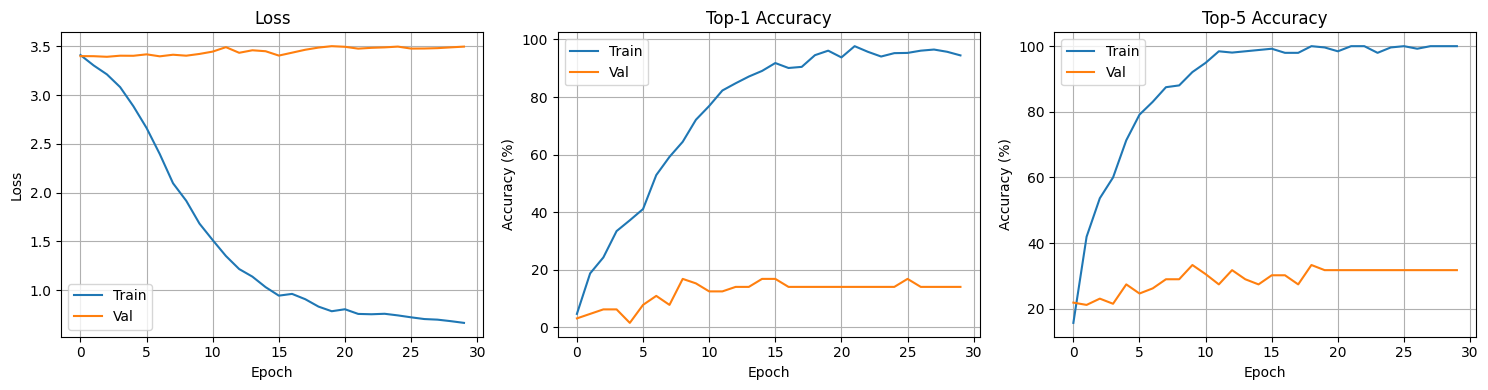

In [18]:
# Gráficas de entrenamiento
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Loss
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(True)

# Top-1 Accuracy
axes[1].plot(history['train_top1'], label='Train')
axes[1].plot(history['val_top1'], label='Val')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Top-1 Accuracy')
axes[1].legend()
axes[1].grid(True)

# Top-5 Accuracy
axes[2].plot(history['train_top5'], label='Train')
axes[2].plot(history['val_top5'], label='Val')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].set_title('Top-5 Accuracy')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig(exp_dir / "training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [19]:
# Cargar mejor modelo y evaluar con confusion matrix
checkpoint = torch.load(exp_dir / "best_model.pt")
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Cargado mejor modelo de época {checkpoint['epoch']}")

# Evaluar en validación con predicciones
val_results = validate(
    model, val_loader, criterion, device, epoch=0, return_predictions=True
)

print(f"\nResultados finales en validación:")
print(f"  Top-1 Accuracy: {val_results['top1_acc']:.1f}%")
print(f"  Top-5 Accuracy: {val_results['top5_acc']:.1f}%")

Cargado mejor modelo de época 9


Epoch 0 [Val]:   0%|          | 0/4 [00:00<?, ?it/s]


Resultados finales en validación:
  Top-1 Accuracy: 16.8%
  Top-5 Accuracy: 29.0%


/tmp/ipython-input-2452946033.py:59: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


Confusion matrix guardada en: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_20260125_024002/confusion_matrix.png


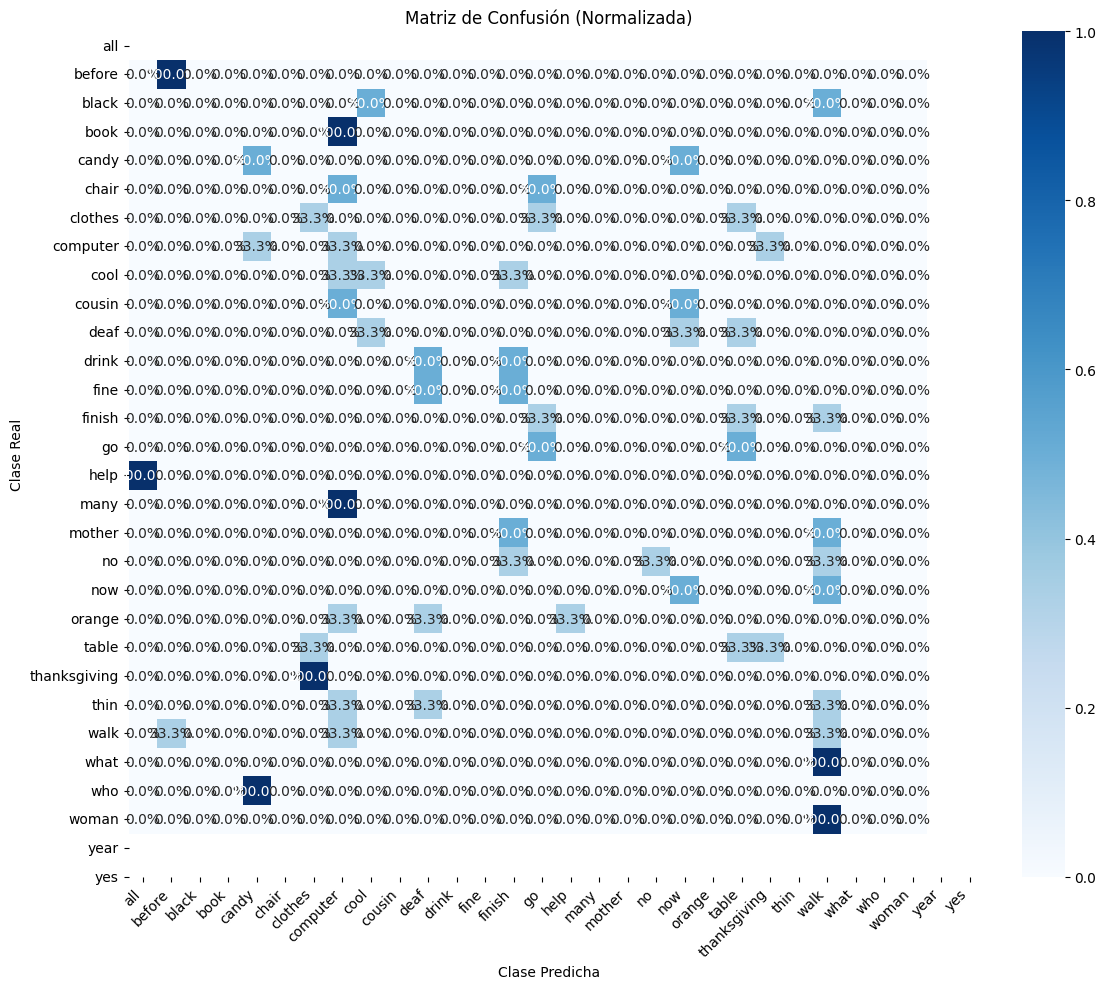

In [20]:
# Confusion Matrix
class_names = [val_dataset.get_gloss(i) for i in range(val_dataset.num_classes)]

plot_confusion_matrix(
    val_results['labels'],
    val_results['predictions'],
    class_names,
    save_path=str(exp_dir / "confusion_matrix.png")
)

## 9. Evaluación en Test Set

In [21]:
# Crear test loader
test_dataset = WLASLDataset(
    root_dir=DATASET_ROOT,
    split="test",
    transform=get_transforms("test"),
    max_frames=MAX_FRAMES,
    sample_strategy="uniform"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True
)

# Evaluar
test_results = validate(
    model, test_loader, criterion, device, epoch=0, return_predictions=True
)

print(f"\n" + "="*60)
print("RESULTADOS FINALES EN TEST SET")
print("="*60)
print(f"Top-1 Accuracy: {test_results['top1_acc']:.1f}%")
print(f"Top-5 Accuracy: {test_results['top5_acc']:.1f}%")
print("="*60)

WLASLDataset [test]: 35 videos, 30 clases


Epoch 0 [Val]:   0%|          | 0/3 [00:00<?, ?it/s]


RESULTADOS FINALES EN TEST SET
Top-1 Accuracy: 10.4%
Top-5 Accuracy: 27.8%


In [22]:
# Guardar resultados finales
final_results = {
    "experiment_name": EXPERIMENT_NAME,
    "best_epoch": best_epoch,
    "val_top1_acc": val_results['top1_acc'],
    "val_top5_acc": val_results['top5_acc'],
    "test_top1_acc": test_results['top1_acc'],
    "test_top5_acc": test_results['top5_acc'],
    "config": config
}

with open(exp_dir / "final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

print(f"\nResultados guardados en: {exp_dir}")
print("Archivos generados:")
for f in exp_dir.iterdir():
    print(f"  - {f.name}")


Resultados guardados en: /content/drive/MyDrive/tfg/experiments/word_recognition/cnn_lstm_20260125_024002
Archivos generados:
  - config.json
  - best_model.pt
  - history.json
  - training_curves.png
  - confusion_matrix.png
  - final_results.json


## 10. Descargar Resultados (Solo Colab)

Si estás en Colab, los resultados ya están guardados en Google Drive.

Para descargarlos a tu ordenador:
1. Ve a Google Drive
2. Navega a `tfg/experiments/word_recognition/<nombre_experimento>/`
3. Descarga la carpeta completa

O usa esta celda para descargar como ZIP:

In [23]:
# Crear ZIP de los resultados y descargar (solo en Colab)
if IN_COLAB:
    import shutil
    from google.colab import files

    # Crear ZIP
    zip_path = f"/content/{EXPERIMENT_NAME}.zip"
    shutil.make_archive(
        zip_path.replace('.zip', ''),
        'zip',
        exp_dir.parent,
        exp_dir.name
    )

    print(f"ZIP creado: {zip_path}")
    print("\nDescargando...")
    files.download(zip_path)
else:
    print("No estás en Colab. Los resultados están en:")
    print(f"  {exp_dir}")

NameError: name 'IN_COLAB' is not defined

## 11. Resumen y Próximos Pasos

### Lo que hemos implementado:

1. **Modelo CNN+LSTM**:
   - ResNet18 como feature extractor (512 dim por frame)
   - LSTM bidireccional para secuencias temporales
   - Clasificador fully-connected

2. **Training pipeline**:
   - Data augmentation (flip, color jitter)
   - AdamW optimizer con weight decay
   - Learning rate scheduler (ReduceLROnPlateau)
   - Gradient clipping para estabilidad

3. **Métricas**:
   - Top-1 y Top-5 accuracy
   - Confusion matrix
   - Gráficas de entrenamiento

### Dónde están los resultados:

- **En Colab**: `Google Drive/tfg/experiments/word_recognition/<nombre_experimento>/`
- **En local**: `05_experiments/word_recognition/<nombre_experimento>/`

### Próximos pasos:

1. **Experimentar con hiperparámetros**:
   - Probar diferentes `hidden_size` (128, 256, 512)
   - Probar con CNN congelado vs fine-tuning
   - Ajustar `max_frames` y `batch_size`

2. **Comparar arquitecturas** (para la tesis):
   - CNN + Transformer
   - 3D CNN (I3D, SlowFast)
   - Vision-Language Models

3. **Escalar el dataset**:
   - Pasar de WLASL30 a WLASL100
   - Eventualmente WLASL300/WLASL2000